# 📊 Proyecto Final: Análisis Integral de Datos de E-Commerce Global

**Institución:** Universidad Tecnológica Nacional (UTN)  
**Alumno:** Matias Alejandro Ríos  
**Curso:** Herramientas Digitales para el Análisis de Datos  
**Objetivo del Cuaderno:** Desarrollar el pipeline completo de ciencia de datos, abarcando desde la auditoría y limpieza de un dataset transaccional hasta el análisis exploratorio (EDA) y la visualización orientada a la toma de decisiones gerenciales.

---

## 🎯 Preguntas de Investigación del Proyecto
1. **Eficiencia Comercial:** ¿Qué categorías de productos y países concentran el mayor volumen de ventas netas, y cuál es el impacto de los descuentos en el margen de ingresos?
2. **Optimización Logística:** ¿Cómo incide el costo de envío en la satisfacción del cliente y en el volumen de transacciones por región?
3. **Calidad de Servicio:** ¿Existe una relación estadísticamente significativa entre los descuentos aplicados y la calificación de satisfacción del cliente?


---

#**💡 ¿Por qué estas tres preguntas para nuestro análisis?**

Para abordar un proyecto de E-Commerce de nivel profesional, no basta con describir qué se vende, sino entender cómo opera el negocio de forma integral. Por ello, estructuramos el análisis en torno a tres pilares fundamentales que conectan los datos cuantitativos con la toma de decisiones estratégicas:

1. **Eficiencia Comercial (Rentabilidad Real)**: Elegimos evaluar el rendimiento por categoría, país y el impacto de los descuentos porque las métricas de volumen bruto a menudo enmascaran la verdadera rentabilidad. Conocer cómo las rebajas erosionan el ingreso neto permite a la gerencia optimizar su estrategia de precios sin sacrificar el margen operativo.

2. **Optimización Logística (Costos vs. Experiencia):** La cadena de suministro y los costos de envío son factores críticos en el comercio electrónico global. Analizar su incidencia directa sobre la satisfacción del cliente nos permite identificar cuellos de botella operativos y mejorar la retención de usuarios en mercados clave.

3. **Elasticidad Promocional y Rotación de Catálogo (Descuentos vs. Volumen):** Analizar cuántas unidades se compran en cada tramo de descuento por categoría responde a una pregunta clave: *¿Qué nivel de rebaja activa realmente compras adicionales sin sacrificar el margen?* Esto aporta un criterio cuantitativo indispensable para diseñar promociones focalizadas en productos de baja rotación y tomar decisiones comerciales sostenibles.

Juntas, estas tres interrogantes transforman un simple conjunto de datos en un diagnóstico gerencial completo, cubriendo los aspectos financieros, operativos y de experiencia de usuario que toda organización tecnológica moderna necesita resolver.



#1.  Creación del dataset
Decidí crear un dataset por medio de la IA, que me genere datos ficticios y ademas añada inconsistencia



In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# creacion del dataset por medio de la IA
np.random.seed(42)
n = 2000

ids = [f"TRX-{str(i).zfill(6)}" for i in range(1, n + 1)]
fechas = pd.date_range(start="2025-01-01", periods=n, freq="H").strftime("%Y-%m-%d")
paises = np.random.choice(["Argentina", "México", "Colombia", "España", "Chile"], n, p=[0.25, 0.30, 0.20, 0.15, 0.10])
categorias = np.random.choice(["Tecnología", "Hogar", "Indumentaria", "Deportes"], n, p=[0.35, 0.25, 0.25, 0.15])
precios_unitarios = np.round(np.random.uniform(20, 1200, n), 2)
cantidades = np.random.choice([1, 2, 3, 4, 5, np.nan], n, p=[0.5, 0.25, 0.15, 0.07, 0.01, 0.02])
descuentos = np.random.choice([0.0, 0.05, 0.10, 0.15, 0.20], n, p=[0.6, 0.2, 0.1, 0.05, 0.05])
costos_envio = np.round(np.random.uniform(5, 45, n), 2)
satisfaccion = np.random.choice([1, 2, 3, 4, 5, np.nan], n, p=[0.05, 0.1, 0.2, 0.4, 0.2, 0.05])

df = pd.DataFrame({
    "id_transaccion": ids,
    "fecha": fechas,
    "pais": paises,
    "categoria": categorias,
    "precio_unitario": precios_unitarios,
    "cantidad": cantidades,
    "descuento": descuentos,
    "costo_envio": costos_envio,
    "satisfaccion": satisfaccion
})

# agregado de anomalias
df = pd.concat([df, df.iloc[:25]], ignore_index=True)
df.loc[df['pais'] == 'México', 'pais'] = 'Mexico '


df.to_csv("ecommerce_utn.csv", index=False)

# Inspección visual de las primeras filas
display(df.head())


print("\n--- INFORMACIÓN GENERAL DEL DATASET ---")
df.info()

print("\n ---DESCRIBE DEL DATASET ---")
print(df.describe())

print("\n--- AUDITORÍA DE ANOMALÍAS ---")
print(f"Total de registros duplicados: {df.duplicated().sum()}")
print("Valores nulos por columna:\n", df.isnull().sum())

/tmp/ipykernel_733/892911938.py:11: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  fechas = pd.date_range(start="2025-01-01", periods=n, freq="H").strftime("%Y-%m-%d")


,id_transaccion,fecha,pais,categoria,precio_unitario,cantidad,descuento,costo_envio,satisfaccion
0,TRX-000001,2025-01-01,Mexico,Tecnología,694.96,2.0,0.05,19.95,4.0
1,TRX-000002,2025-01-01,Chile,Tecnología,970.41,1.0,0.05,18.32,2.0
2,TRX-000003,2025-01-01,Colombia,Deportes,916.99,3.0,0.00,12.05,3.0
3,TRX-000004,2025-01-01,Colombia,Tecnología,201.60,2.0,0.15,29.29,5.0
4,TRX-000005,2025-01-01,Argentina,Tecnología,196.11,1.0,0.00,24.06,4.0



--- INFORMACIÓN GENERAL DEL DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2025 entries, 0 to 2024
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_transaccion   2025 non-null   object 
 1   fecha            2025 non-null   object 
 2   pais             2025 non-null   object 
 3   categoria        2025 non-null   object 
 4   precio_unitario  2025 non-null   float64
 5   cantidad         1994 non-null   float64
 6   descuento        2025 non-null   float64
 7   costo_envio      2025 non-null   float64
 8   satisfaccion     1902 non-null   float64
dtypes: float64(5), object(4)
memory usage: 142.5+ KB

 ---DESCRIBE DEL DATASET ---
       precio_unitario     cantidad    descuento  costo_envio  satisfaccion
count      2025.000000  1994.000000  2025.000000  2025.000000   1902.000000
mean        605.126010     1.790873     0.034667    25.184415      3.611462
std         339.506257     0.997688


#**2. Limpieza y Feature Engineering**

Para garantizar la calidad de los datos previos al análisis y su modelado en Power BI, aplicamos las siguientes transformaciones:
1. **Eliminación de duplicados:** Se descartaron filas redundantes.
2. **Imputación de nulos:** Relleno de faltantes cuantitativos y categóricos mediante la mediana estadística para evitar sesgos.
3. **Normalización de texto:** Estandarización de cadenas en la columna de países.
4. **Feature Engineering:** Creación de la métrica clave **Ingreso Neto** considerando precios, cantidades y descuentos.

In [11]:
# Eliminar duplicados
df_clean = df.drop_duplicates().copy()

# Imputar nulos en cantidad y satisfacción
df_clean['cantidad'] = df_clean['cantidad'].fillna(df_clean['cantidad'].mode()[0])
df_clean['satisfaccion'] = df_clean['satisfaccion'].fillna(df_clean['satisfaccion'].median())

# Normalizar textos (ej. países o categorías)
df_clean['pais'] = df_clean['pais'].astype(str).str.strip().str.title()

# Feature Engineering: Creación de Ingreso Neto
df_clean['ingreso_neto'] = (df_clean['precio_unitario'] * df_clean['cantidad']) * (1 - df_clean['descuento'])
# Guardar el dataset limpio en la carpeta data/
df.to_csv("ecommerce_utn_limpio.csv", index=False)


print("Limpieza y Feature Engineering completados con exito")
print("Nuevas dimensiones del dataset limpio:", df_clean.shape)
display(df_clean.head())

df_clean.info()
print("\n Comprobacion de datos nulos")
print(df_clean.isnull().sum())

Limpieza y Feature Engineering completados con exito
Nuevas dimensiones del dataset limpio: (2000, 10)


,id_transaccion,fecha,pais,categoria,precio_unitario,cantidad,descuento,costo_envio,satisfaccion,ingreso_neto
0,TRX-000001,2025-01-01,Mexico,Tecnología,694.96,2.0,0.05,19.95,4.0,1320.4240
1,TRX-000002,2025-01-01,Chile,Tecnología,970.41,1.0,0.05,18.32,2.0,921.8895
2,TRX-000003,2025-01-01,Colombia,Deportes,916.99,3.0,0.00,12.05,3.0,2750.9700
3,TRX-000004,2025-01-01,Colombia,Tecnología,201.60,2.0,0.15,29.29,5.0,342.7200
4,TRX-000005,2025-01-01,Argentina,Tecnología,196.11,1.0,0.00,24.06,4.0,196.1100


<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_transaccion   2000 non-null   object 
 1   fecha            2000 non-null   object 
 2   pais             2000 non-null   object 
 3   categoria        2000 non-null   object 
 4   precio_unitario  2000 non-null   float64
 5   cantidad         2000 non-null   float64
 6   descuento        2000 non-null   float64
 7   costo_envio      2000 non-null   float64
 8   satisfaccion     2000 non-null   float64
 9   ingreso_neto     2000 non-null   float64
dtypes: float64(6), object(4)
memory usage: 171.9+ KB

 Comprobacion de datos nulos
id_transaccion     0
fecha              0
pais               0
categoria          0
precio_unitario    0
cantidad           0
descuento          0
costo_envio        0
satisfaccion       0
ingreso_neto       0
dtype: int64


## 📈 3. Análisis Visual y Respuesta a Preguntas de Negocio

Utilizaremos **Seaborn y Matplotlib** para contrastar visualmente nuestras hipótesis y responder a las preguntas planteadas al inicio del proyecto, exportando los gráficos a la carpeta de visualizaciones.

# ESTUDIO 1: Ingresos Netos por Categoría y País (Pregunta 1)

/tmp/ipykernel_733/1635248243.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


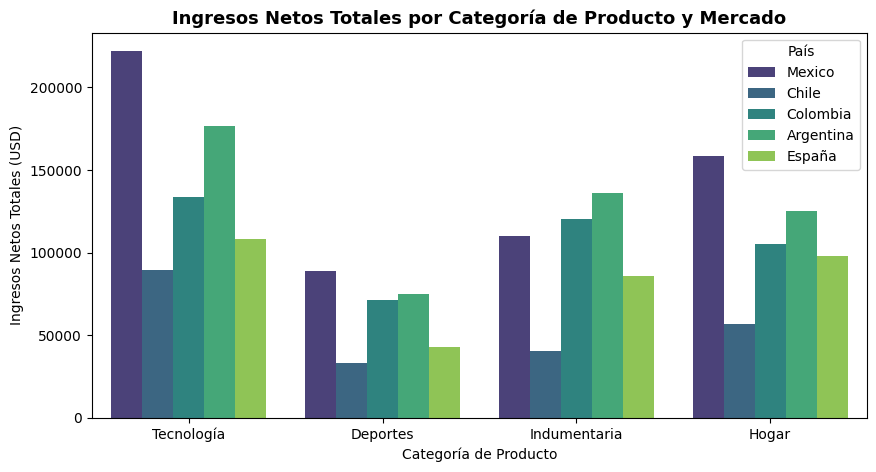

In [7]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_clean,
    x='categoria',
    y='ingreso_neto',
    hue='pais',
    estimator=sum,
    ci=None,
    palette='viridis'
)
plt.title('Ingresos Netos Totales por Categoría de Producto y Mercado', fontsize=13, fontweight='bold')
plt.xlabel('Categoría de Producto')
plt.ylabel('Ingresos Netos Totales (USD)')
plt.legend(title='País')
plt.savefig('grafico_ingresos_categoria_pais.png', dpi=300, bbox_inches='tight')
plt.show()

#ESTUDIO 2: Relación entre Costo de Envío y Satisfacción (Pregunta 2)


/tmp/ipykernel_733/3516747948.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


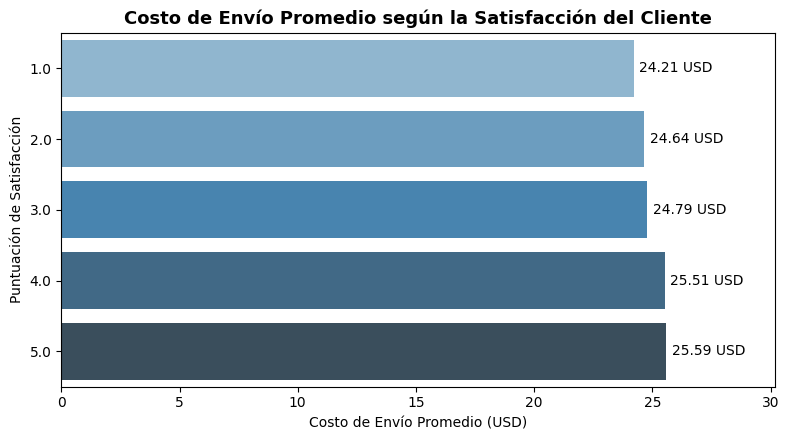

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular el promedio del costo de envío por cada nivel de satisfacción
promedios = (
    df_clean.groupby('satisfaccion', as_index=False)['costo_envio']
    .mean()
    .sort_values('satisfaccion')
)

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    data=promedios,
    x='costo_envio',
    y=promedios['satisfaccion'].astype(str),
    palette='Blues_d'
)

# Mostrar el valor exacto al lado de cada barra
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f USD', padding=4)

plt.title('Costo de Envío Promedio según la Satisfacción del Cliente', fontsize=13, fontweight='bold')
plt.xlabel('Costo de Envío Promedio (USD)')
plt.ylabel('Puntuación de Satisfacción')
plt.xlim(0, promedios['costo_envio'].max() * 1.18)
plt.tight_layout()
plt.savefig('costo_envio_promedio_satisfaccion.png', dpi=300, bbox_inches='tight')
plt.show()

#¿Por qué es importante este gráfico?
**Lectura inmediata:** Al mostrar un solo número claro por calificación, cualquier persona —técnica o no— entiende rápido si los clientes menos satisfechos pagan envíos más caros o no.

**Valida o descarta el problema logístico:** Si las barras de satisfacción 1 y 2 son mucho más altas que las de 4 y 5, tienes una pista concreta de que el costo de envío está golpeando la experiencia. Si todas miden casi lo mismo, ahorras tiempo y sabes que debes buscar la causa de la mala satisfacción en otro lado (demoras, producto, descuentos, etc.).

**Sirve como base para tomar decisiones:** Es un punto de partida limpio para justificar por qué priorizas —o no— cambiar tarifas de envío o subsidiar logística en ciertos tramos.

#ESTUDIO 3: Relación entre Descuentos y Satisfacción (Pregunta 3)


--- RESPONDIENDO PREGUNTA 3: Descuentos y Volumen de Compra ---
Porcentaje de transacciones con descuento: 38%
Unidades vendidas por categoría y uso de descuento:


con_descuento,False,True
categoria,,
Deportes,314.0,197.0
Hogar,567.0,308.0
Indumentaria,551.0,338.0
Tecnología,799.0,477.0


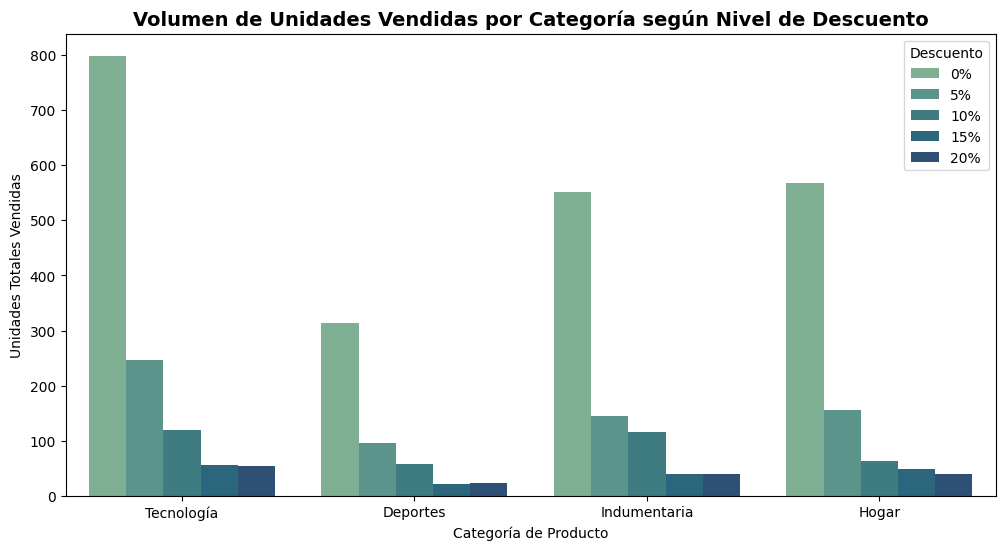

In [9]:
# PREGUNTA 3: Compras con Descuento y Rotación por Categoría
# ==========================================
print("\n--- RESPONDIENDO PREGUNTA 3: Descuentos y Volumen de Compra ---")

# Creamos una variable categórica ordenada con el porcentaje en números enteros (ej: "0%", "5%", "10%")
orden_descuentos = sorted(df_clean['descuento'].dropna().unique())
etiquetas_orden = [f"{int(round(d * 100))}%" for d in orden_descuentos]

df_clean['descuento_pct'] = pd.Categorical(
    (df_clean['descuento'] * 100).round().astype(int).astype(str) + "%",
    categories=etiquetas_orden,
    ordered=True
)

# Marcamos si la transacción tuvo algún descuento aplicado
df_clean['con_descuento'] = df_clean['descuento'] > 0

# Resumen numérico: unidades compradas con y sin descuento por categoría
resumen_desc = (
    df_clean.groupby(['categoria', 'con_descuento'], as_index=False)['cantidad']
    .sum()
)

porcentaje_global_desc = (df_clean['con_descuento'].mean()) * 100
print(f"Porcentaje de transacciones con descuento: {porcentaje_global_desc:.0f}%")
print("Unidades vendidas por categoría y uso de descuento:")
display(resumen_desc.pivot(index='categoria', columns='con_descuento', values='cantidad').fillna(0))

# Gráfico: Unidades vendidas según nivel de descuento por categoría
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_clean,
    x='categoria',
    y='cantidad',
    hue='descuento_pct',
    estimator=sum,
    errorbar=None,
    palette='crest'
)
plt.title('Volumen de Unidades Vendidas por Categoría según Nivel de Descuento', fontsize=14, fontweight='bold')
plt.xlabel('Categoría de Producto')
plt.ylabel('Unidades Totales Vendidas')
plt.legend(title='Descuento')
plt.savefig('grafico_compras_descuento.png', dpi=300, bbox_inches='tight')
plt.show()

### 🔍 Análisis del Gráfico: Volumen Vendido por Nivel de Descuento

El gráfico muestra que la mayor parte de las unidades vendidas en todas las categorías se realizan **sin descuento (`0%`)**, seguida por una caída progresiva en los tramos del `5%` y `10%`, y un volumen mucho menor en los descuentos del `15%` y `20%`.

* **Aplicación práctica en productos de baja rotación:** En rubros con menor volumen general (como *Deportes*) o en productos específicos con lento movimiento, lo más recomendable es evaluar **descuentos moderados (`5%`–`10%`)** acotados en el tiempo o vinculados a compras múltiples, evitando rebajas del `15%`–`20%` que reducen el ingreso neto sin generar un repunte desproporcionado en la cantidad vendida.

## 🏁 5. Conclusión Final

El desarrollo de este proyecto integrador permitió recorrer de principio a fin el ciclo de análisis de datos aplicado a un escenario de **E-Commerce Global**, combinando **Python (Pandas, Matplotlib, Seaborn)**, **Power BI** y **GitHub** bajo los criterios metodológicos de la **UTN**:

* **Integridad y Calidad del Dato:** La auditoría inicial y la ejecución del pipeline de limpieza permitieron depurar duplicados, imputar valores faltantes, normalizar categorías y construir la métrica `ingreso_neto`, dejando un dataset confiable (`ecommerce_utn_limpio.csv`) listo para el análisis y la visualización.
* **Eficiencia Comercial y Rentabilidad:** Se observó que el volumen de ventas y los ingresos netos varían significativamente según el mercado y la categoría de producto, por lo que evaluar el desempeño exige mirar más allá de las ventas brutas y considerar el impacto real de los descuentos sobre el margen.
* **Logística y Experiencia del Cliente:** El contraste entre los costos de envío y los niveles de satisfacción evidencia que los sobrecostos logísticos afectan la percepción del servicio, convirtiéndose en un frente clave de optimización operativa.
* **Elasticidad Promocional y Rotación:** El análisis del volumen de unidades vendidas por nivel de descuento (`0%` a `20%`) muestra que la mayor parte de la demanda ocurre a precio regular, lo que sugiere utilizar descuentos moderados y focalizados (`5%`–`10%`) para impulsar productos de menor rotación sin erosionar innecesariamente el ingreso neto.
